
# 03 - Self-Attention

## Overview
Implemented a Self-Attention mechanism using PyTorch to understand relationships between tokens in a sequence. The mechanism allows each token to focus on relevant previous tokens while preventing access to future tokens through causal masking.

## Key Implementation
- Loaded preprocessed training and validation datasets from Task 1.
- Reused the existing character-level tokenizer and vocabulary.
- Converted token IDs into embedding vectors.
- Implemented Query, Key, and Value transformations.
- Calculated scaled attention scores.
- Applied causal masking to prevent future-token access.
- Used Softmax to calculate attention weights.
- Generated attention outputs using weighted value vectors.
- Visualized attention weights using a heatmap.
- Verified causal masking functionality.

## Technologies
Python, PyTorch, NumPy, Matplotlib, JSON

## Model Configuration

| Parameter | Value |
|---|---|
| Batch Size | 32 |
| Block Size | 8 |
| Embedding Size | 32 |
| Attention Type | Causal Self-Attention |

## Result
Successfully implemented and tested a Self-Attention mechanism that captures relationships between tokens using Query, Key, and Value representations. This implementation establishes the foundation for Multi-Head Attention and Transformer architecture.


In [6]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import json
from pathlib import Path
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:

# Get the main project folder
project_dir = Path.cwd()

# Check project directory
if not (project_dir / "data").exists():
    project_dir = project_dir.parent

# Load processed datasets from Task 1
train_data = np.load(project_dir / "data" / "train_ids.npy")
val_data = np.load(project_dir / "data" / "val_ids.npy")

# Load tokenizer information from Task 1
with open(project_dir / "data" / "tokenizer.json", "r") as file:
    tokenizer = json.load(file)

# Get vocabulary information
characters = tokenizer["characters"]

# Create character-to-integer mapping
stoi = {ch: i for i, ch in enumerate(characters)}

# Create integer-to-character mapping
itos = {i: ch for i, ch in enumerate(characters)}

# Get vocabulary size
vocab_size = len(characters)

# Set device
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Task 1 data loaded successfully!")
print("Training data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)
print("Vocabulary size:", vocab_size)
print("Device:", device)


Task 1 data loaded successfully!
Training data shape: (1003854,)
Validation data shape: (111540,)
Vocabulary size: 65
Device: cpu


In [15]:
# Load Data

# Set model and output directories
model_dir = project_dir / "models"
output_dir = project_dir / "outputs"

# Check Bigram model
model_path = model_dir / "bigram_model.pth"

if model_path.exists():
    print("Task 2 Bigram model found!")
else:
    print("Task 2 Bigram model not found!")

# Check generated text
generated_path = output_dir / "generated_text.txt"

if generated_path.exists():
    print("Task 2 generated text found!")
else:
    print("Task 2 generated text not found!")

print("\nTask 2 output verification completed!")

Task 2 Bigram model found!
Task 2 generated text found!

Task 2 output verification completed!


In [16]:
# Convert Data into PyTorch Tensors

# Convert NumPy arrays into PyTorch tensors
train_data = torch.tensor(train_data, dtype=torch.long)
val_data = torch.tensor(val_data, dtype=torch.long)

# Set sequence length
block_size = 8

print("Training tensor shape:", train_data.shape)
print("Validation tensor shape:", val_data.shape)

Training tensor shape: torch.Size([1003854])
Validation tensor shape: torch.Size([111540])


C:\Users\PREMIUM\AppData\Local\Temp\ipykernel_8684\1731638460.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_data = torch.tensor(train_data, dtype=torch.long)
C:\Users\PREMIUM\AppData\Local\Temp\ipykernel_8684\1731638460.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_data = torch.tensor(val_data, dtype=torch.long)


In [17]:
# Set Model Configuration

# Model configuration
batch_size = 32
block_size = 8
embedding_size = 32

print("Batch Size:", batch_size)
print("Block Size:", block_size)
print("Embedding Size:", embedding_size)


Batch Size: 32
Block Size: 8
Embedding Size: 32


In [18]:
# Create Batch Generation Function

def get_batch(split):

    data = train_data if split == "train" else val_data

    ix = torch.randint(
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1] for i in ix
    ])

    return x.to(device), y.to(device)


# Generate sample batch
x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([32, 8])
Target shape: torch.Size([32, 8])


In [19]:
# Create Token Embeddings

# Convert token IDs into embedding vectors
token_embedding = nn.Embedding(
    vocab_size,
    embedding_size
).to(device)

x_embeddings = token_embedding(x)

print("Token embedding shape:", x_embeddings.shape)

Token embedding shape: torch.Size([32, 8, 32])


In [20]:
# Implement Self-Attention

class SelfAttentionHead(nn.Module):

    def __init__(self, head_size, block_size):
        super().__init__()

        self.query = nn.Linear(head_size, head_size, bias=False)
        self.key = nn.Linear(head_size, head_size, bias=False)
        self.value = nn.Linear(head_size, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.head_size = head_size

    def forward(self, x):

        B, T, C = x.shape

        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        # Calculate attention scores
        scores = q @ k.transpose(-2, -1)

        # Scale attention scores
        scores = scores / (self.head_size ** 0.5)

        # Apply causal masking
        scores = scores.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        # Calculate attention probabilities
        weights = F.softmax(scores, dim=-1)

        # Calculate attention output
        output = weights @ v

        return output, weights


print("Self-Attention class created successfully!")

Self-Attention class created successfully!


In [21]:
# Apply Self-Attention

# Create Self-Attention layer
self_attention = SelfAttentionHead(
    embedding_size,
    block_size
).to(device)

# Apply attention
output, attention_weights = self_attention(x_embeddings)

print("Input shape:", x_embeddings.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", attention_weights.shape)

Input shape: torch.Size([32, 8, 32])
Output shape: torch.Size([32, 8, 32])
Attention weights shape: torch.Size([32, 8, 8])


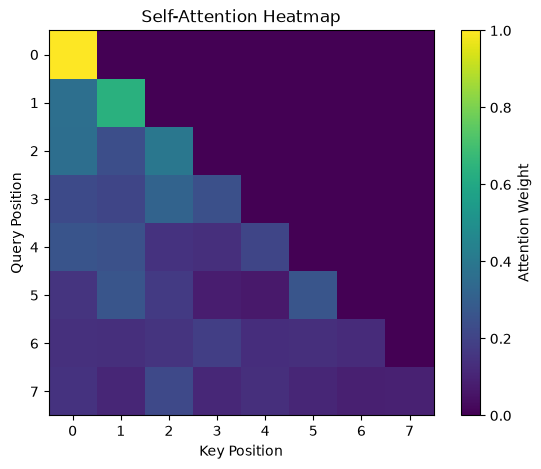

In [22]:
# Visualize Attention Weights

# Get attention weights for first sample
attention_map = attention_weights[0].detach().cpu().numpy()

plt.figure(figsize=(7, 5))

plt.imshow(attention_map, cmap="viridis")
plt.colorbar(label="Attention Weight")

plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.title("Self-Attention Heatmap")

plt.show()

In [23]:
# Verify Causal Masking

# Check whether future tokens are masked
future_weights = torch.triu(
    attention_weights,
    diagonal=1
)

print(
    "Future tokens masked:",
    torch.all(future_weights == 0).item()
)

Future tokens masked: True


In [24]:
# Display Attention Output

# Display output for first sample
print("Self-Attention Output:")
print(output[0].detach().cpu())

print("\nSelf-Attention completed successfully!")

Self-Attention Output:
tensor([[ 7.1107e-01,  4.1027e-01, -2.3443e-02,  4.1831e-01, -1.8005e-01,
         -3.7102e-01, -1.6721e-01, -7.9291e-02,  1.5418e-04, -1.5598e-01,
          5.6734e-02,  2.0540e-01, -6.6843e-01,  9.3093e-01, -1.9500e-01,
          4.4795e-01,  5.7512e-01,  3.5103e-02, -6.9795e-02,  6.4654e-02,
         -8.0505e-01,  7.0493e-01,  3.4629e-01,  6.4540e-02, -1.6451e-01,
          3.5419e-01, -1.1076e-01, -7.0327e-02, -3.2976e-01,  1.0378e+00,
          4.7849e-01,  2.1694e-01],
        [-2.8772e-01, -4.1914e-01,  1.5821e-01,  3.5321e-01, -2.3337e-01,
         -5.1302e-01, -2.8063e-01, -7.6509e-01, -3.6071e-01, -1.8194e-01,
         -1.1658e-01,  1.6228e-02, -2.4070e-01,  4.4213e-01,  2.2455e-01,
          4.0834e-01, -4.1398e-01, -3.0013e-01, -3.4403e-01, -2.1309e-01,
         -1.6321e-01,  3.2418e-01,  2.8108e-01, -7.9228e-02,  2.2733e-01,
          4.5419e-01,  3.5797e-02,  2.2675e-02,  5.8991e-02,  2.6189e-02,
          7.2735e-01, -5.5036e-02],
        [ 1.6878e